In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv
/kaggle/input/datasets/dgawlik/nyse/fundamentals.csv
/kaggle/input/datasets/dgawlik/nyse/prices.csv
/kaggle/input/datasets/dgawlik/nyse/securities.csv


In [2]:
df = pd.read_csv("/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv")
df.head()

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [3]:
df.shape

(851264, 7)

on a ici 851264 lignes et 7 colonnes :(date	symbol	open	close	low	high	volume)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB


In [5]:
df.isnull().sum() 

date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

// y a pas de valeurs null au niveau du dataset

In [6]:
nbre = df.duplicated().sum()
print (nbre)

0


y a pas de valeurs dupliquées au niveau du dataset 

dapres ce qui precede on remarque que la date est de type object :  date    851264 non-null  object  donc on doit la convertire en datetime

In [8]:
df["date"] = pd.to_datetime(df["date"],errors = "coerce" )

In [9]:
print(df["date"].dtype)

datetime64[ns]


verification de type 

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


verifier combien action existe au niveau du dataset

In [11]:
nombre_symbol = df["symbol"].nunique()
print (nombre_symbol)


liste_symbol = df["symbol"].unique()
print (liste_symbol)

501
['WLTW' 'A' 'AAL' 'AAP' 'AAPL' 'ABC' 'ABT' 'ACN' 'ADBE' 'ADI' 'ADM' 'ADP'
 'ADS' 'ADSK' 'AEE' 'AEP' 'AES' 'AET' 'AFL' 'AGN' 'AIG' 'AIZ' 'AJG' 'AKAM'
 'ALB' 'ALK' 'ALL' 'ALXN' 'AMAT' 'AME' 'AMG' 'AMGN' 'AMP' 'AMT' 'AMZN'
 'AN' 'ANTM' 'AON' 'APA' 'APC' 'APD' 'APH' 'ARNC' 'ATVI' 'AVB' 'AVGO'
 'AVY' 'AWK' 'AXP' 'AYI' 'AZO' 'BA' 'BAC' 'BAX' 'BBBY' 'BBT' 'BBY' 'BCR'
 'BDX' 'BEN' 'BHI' 'BIIB' 'BK' 'BLK' 'BLL' 'BMY' 'BSX' 'BWA' 'BXP' 'C'
 'CA' 'CAG' 'CAH' 'CAT' 'CB' 'CBG' 'CBS' 'CCI' 'CCL' 'CELG' 'CERN' 'CF'
 'CHD' 'CHK' 'CHRW' 'CI' 'CINF' 'CL' 'CLX' 'CMA' 'CMCSA' 'CME' 'CMG' 'CMI'
 'CMS' 'CNC' 'CNP' 'COF' 'COG' 'COH' 'COL' 'COO' 'COP' 'COST' 'CPB' 'CRM'
 'CSCO' 'CSX' 'CTAS' 'CTL' 'CTSH' 'CTXS' 'CVS' 'CVX' 'CXO' 'D' 'DAL' 'DD'
 'DE' 'DFS' 'DG' 'DGX' 'DHI' 'DHR' 'DIS' 'DISCA' 'DISCK' 'DLR' 'DLTR'
 'DNB' 'DOV' 'DOW' 'DPS' 'DRI' 'DTE' 'DUK' 'DVA' 'DVN' 'EA' 'EBAY' 'ECL'
 'ED' 'EFX' 'EIX' 'EL' 'EMN' 'EMR' 'ENDP' 'EOG' 'EQIX' 'EQR' 'EQT' 'ES'
 'ESRX' 'ESS' 'ETFC' 'ETN' 'ETR' 'EW' 'EXC' 'EXPD' '

 verifier la periode de dates 

In [12]:
date_min = df['date'].min()
date_max = df['date'].max()
print("la periode entre  :", date_min,"  et  ", date_max)


la periode entre  : 2010-01-04 00:00:00   et   2016-12-30 00:00:00


In [13]:
df.describe()

,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


les remarques d apres ca : 
- open	close	low	high  sont autour de 64 et 65
- mais le volume est entre 0 et 859 milions  =>  on peut dire peut etre y a des outliers  car on a aussi ecaart type est plus grand que la moyenne : grande dispersion a cause des outliers
  
=> Donc echelle du volume est tres grand par rapport aux (open/close/low/high) : il faut normaliser&standardiser pour avoir meme echelle des donnees
- on peut remarquer aussi que la distribution est asymetrique puisque pour open/close/low/high  et le volume on a la moyenne est plus grande par rapport au mediane 

In [14]:
df.corr(numeric_only=True)

,open,close,low,high,volume
open,1.000000,0.999845,0.999914,0.999928,-0.132526
close,0.999845,1.000000,0.999926,0.999925,-0.132675
low,0.999914,0.999926,1.000000,0.999889,-0.133087
high,0.999928,0.999925,0.999889,1.000000,-0.132168
volume,-0.132526,-0.132675,-0.133087,-0.132168,1.000000


on va utiliser les graphe pour bien visualiser les choses 

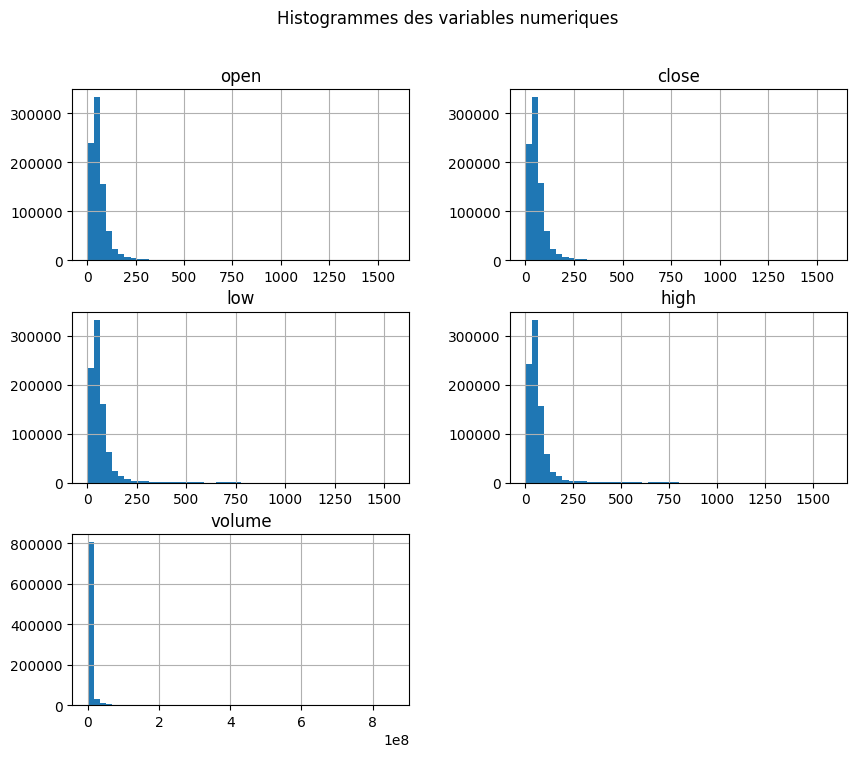

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['open','close','low','high','volume']
df[num_cols].hist(bins=50, figsize=(10,8))
plt.suptitle("Histogrammes des variables numeriques")
plt.show()


- cet histogramme confirme ce que on a deja dit concerant la distrubition qui est asymetrique 
- grande majorite des donnees  concentre a gauche de axe des x : ca signifie que la moyenne superieure a la mediane
- Open, close, low, high ont la meme forme  Donc ces variables sont correles

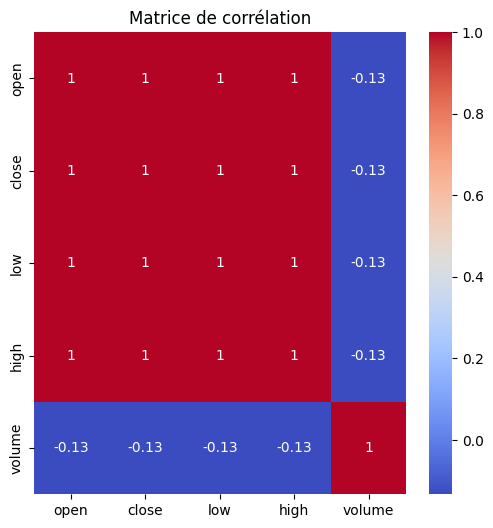

In [16]:
plt.figure(figsize=(6,6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Matrice de corrélation")
plt.show()


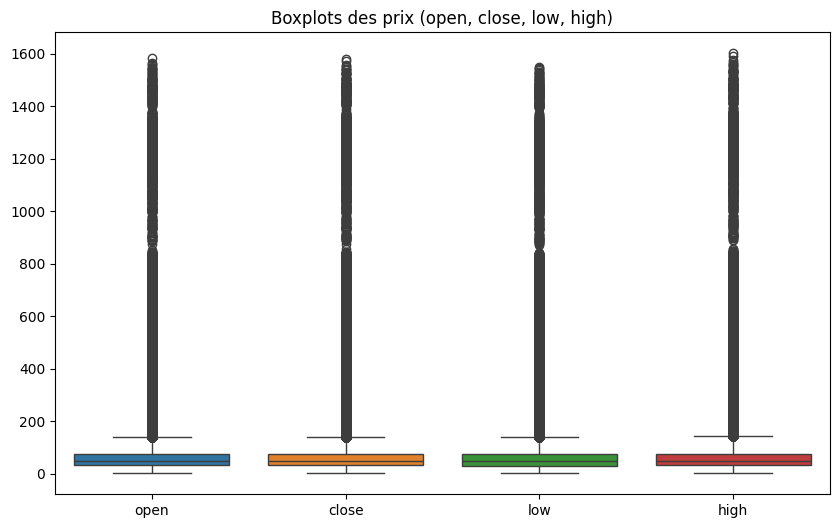

In [17]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['open','close','low','high']])
plt.title("Boxplots des prix (open, close, low, high)")
plt.show()

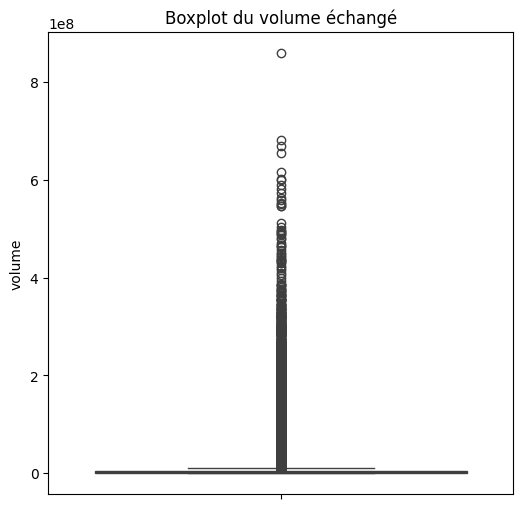

In [18]:
plt.figure(figsize=(6,6))
sns.boxplot(y=df['volume'])
plt.title("Boxplot du volume échangé")
plt.show()

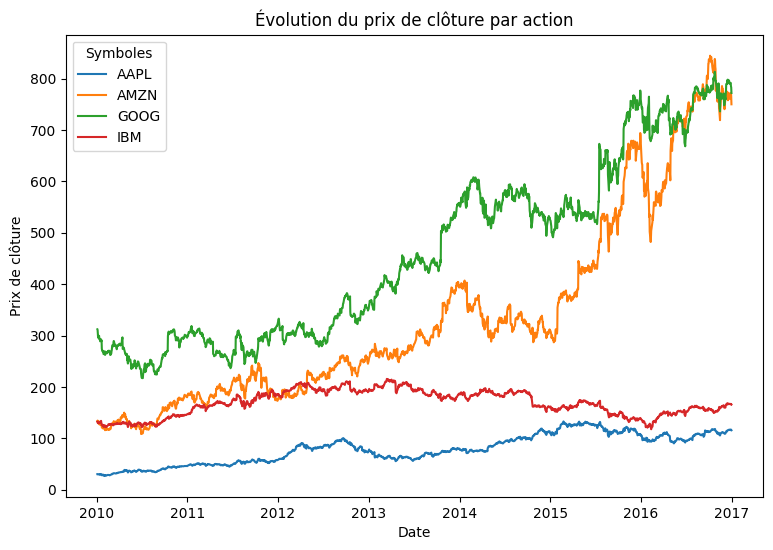

In [19]:
symbols = ["AAPL", "GOOG", "AMZN", "IBM"]
subset = df[df["symbol"].isin(symbols)]

plt.figure(figsize=(9,6))
sns.lineplot(x="date", y="close", hue="symbol", data=subset)
plt.title("Évolution du prix de clôture par action")
plt.xlabel("Date")
plt.ylabel("Prix de clôture")
plt.legend(title="Symboles")
plt.show()

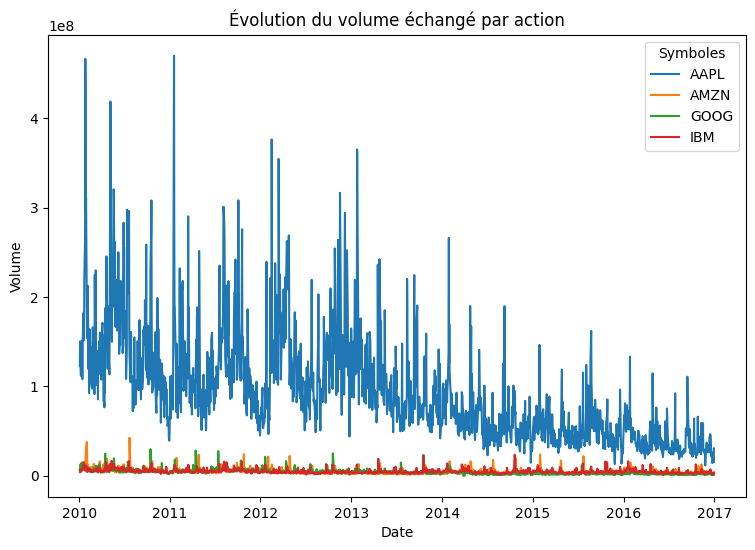

In [20]:
plt.figure(figsize=(9,6))
sns.lineplot(x="date", y="volume", hue="symbol", data=subset)
plt.title("Évolution du volume échangé par action")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.legend(title="Symboles")
plt.show()

La cible : avec les infos de lundi, prédire le close de mardi. C’est une vraie prédiction du futur

In [21]:
# Filtrer les 4 actions
symbols = ["AAPL", "GOOG", "AMZN", "IBM"]
data = df[df["symbol"].isin(symbols)].copy()
print (data)

             date symbol        open       close         low        high  \
254    2010-01-04   AAPL   30.490000   30.572857   30.340000   30.642857   
284    2010-01-04   AMZN  136.250000  133.899994  133.139999  136.610001   
439    2010-01-04   GOOG  312.304948  312.205308  310.955001  313.580158   
470    2010-01-04    IBM  131.179993  132.449997  130.850006  132.970001   
721    2010-01-05   AAPL   30.657143   30.625713   30.464285   30.798571   
...           ...    ...         ...         ...         ...         ...   
850496 2016-12-29    IBM  166.020004  166.600006  166.000000  166.990005   
850767 2016-12-30   AAPL  116.650002  115.820000  115.430000  117.199997   
850799 2016-12-30   AMZN  766.469971  749.869995  748.280029  767.400024   
850963 2016-12-30   GOOG  782.750000  771.820007  770.409973  782.780029   
850996 2016-12-30    IBM  166.440002  165.990005  165.500000  166.699997   

             volume  
254     123432400.0  
284       7599900.0  
439       3927000.0  

garde uniquement les lignes dont le symbol est dans la liste car entraîner sur 501 actions serait très long, surtout avec le GridSearch

In [22]:
# Trier par symbol puis par date
data = data.sort_values(["symbol", "date"]).reset_index(drop=True)
print (data)

           date symbol        open       close         low        high  \
0    2010-01-04   AAPL   30.490000   30.572857   30.340000   30.642857   
1    2010-01-05   AAPL   30.657143   30.625713   30.464285   30.798571   
2    2010-01-06   AAPL   30.625713   30.138571   30.107143   30.747143   
3    2010-01-07   AAPL   30.250000   30.082857   29.864286   30.285715   
4    2010-01-08   AAPL   30.042856   30.282858   29.865715   30.285715   
...         ...    ...         ...         ...         ...         ...   
7043 2016-12-23    IBM  167.000000  166.710007  166.449997  167.490005   
7044 2016-12-27    IBM  166.979996  167.139999  166.850006  167.979996   
7045 2016-12-28    IBM  167.289993  166.190002  166.000000  167.740005   
7046 2016-12-29    IBM  166.020004  166.600006  166.000000  166.990005   
7047 2016-12-30    IBM  166.440002  165.990005  165.500000  166.699997   

           volume  
0     123432400.0  
1     150476200.0  
2     138040000.0  
3     119282800.0  
4     11190

etape suivante (shift(-1)) prend  la ligne den  comme etant le jour suivant , Si les dates ne sont pas dans l ordre, la ligne du dessous n est pas forcement le lendemain, et la cible serait fausse

La colonne close ne change pas
On cree une nouvelle colonne target qui contient le close du lendemain

In [23]:
# la cible : close du jour suivant, action par action
data["target"] = data.groupby("symbol")["close"].shift(-1)
print (data)

           date symbol        open       close         low        high  \
0    2010-01-04   AAPL   30.490000   30.572857   30.340000   30.642857   
1    2010-01-05   AAPL   30.657143   30.625713   30.464285   30.798571   
2    2010-01-06   AAPL   30.625713   30.138571   30.107143   30.747143   
3    2010-01-07   AAPL   30.250000   30.082857   29.864286   30.285715   
4    2010-01-08   AAPL   30.042856   30.282858   29.865715   30.285715   
...         ...    ...         ...         ...         ...         ...   
7043 2016-12-23    IBM  167.000000  166.710007  166.449997  167.490005   
7044 2016-12-27    IBM  166.979996  167.139999  166.850006  167.979996   
7045 2016-12-28    IBM  167.289993  166.190002  166.000000  167.740005   
7046 2016-12-29    IBM  166.020004  166.600006  166.000000  166.990005   
7047 2016-12-30    IBM  166.440002  165.990005  165.500000  166.699997   

           volume      target  
0     123432400.0   30.625713  
1     150476200.0   30.138571  
2     138040000

decale la colonne close d’une ligne vers le haut
Le résultat est stocké dans une nouvelle colonne target

In [24]:
data["target"].isnull().sum()

np.int64(4)

In [25]:
# Supprimer les lignes NaN
data = data.dropna(subset=["target"]).reset_index(drop=True)
print (data)

           date symbol        open       close         low        high  \
0    2010-01-04   AAPL   30.490000   30.572857   30.340000   30.642857   
1    2010-01-05   AAPL   30.657143   30.625713   30.464285   30.798571   
2    2010-01-06   AAPL   30.625713   30.138571   30.107143   30.747143   
3    2010-01-07   AAPL   30.250000   30.082857   29.864286   30.285715   
4    2010-01-08   AAPL   30.042856   30.282858   29.865715   30.285715   
...         ...    ...         ...         ...         ...         ...   
7039 2016-12-22    IBM  167.360001  167.059998  166.580002  168.229996   
7040 2016-12-23    IBM  167.000000  166.710007  166.449997  167.490005   
7041 2016-12-27    IBM  166.979996  167.139999  166.850006  167.979996   
7042 2016-12-28    IBM  167.289993  166.190002  166.000000  167.740005   
7043 2016-12-29    IBM  166.020004  166.600006  166.000000  166.990005   

           volume      target  
0     123432400.0   30.625713  
1     150476200.0   30.138571  
2     138040000

Le dernier jour de chaque action n’a pas de lendemain, donc son target vaut NaN (4 lignes au total).

Verification 

In [26]:
print(data.shape)
print(data.isnull().sum())

(7044, 8)
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
target    0
dtype: int64


In [27]:
data.head()

,date,symbol,open,close,low,high,volume,target
0,2010-01-04,AAPL,30.490000,30.572857,30.340000,30.642857,123432400.0,30.625713
1,2010-01-05,AAPL,30.657143,30.625713,30.464285,30.798571,150476200.0,30.138571
2,2010-01-06,AAPL,30.625713,30.138571,30.107143,30.747143,138040000.0,30.082857
3,2010-01-07,AAPL,30.250000,30.082857,29.864286,30.285715,119282800.0,30.282858
4,2010-01-08,AAPL,30.042856,30.282858,29.865715,30.285715,111902700.0,30.015715


split  et normalisation

In [28]:
features = ["open", "high", "low", "close", "volume"]

# on va faire le split on se basant sur la date 
train = data[data["date"] < "2016-01-01"]
test = data[data["date"] >= "2016-01-01"]

In [29]:
X_train, y_train = train[features], train["target"]
X_test,  y_test  = test[features],  test["target"]

In [30]:
print(X_train.shape, X_test.shape)

(6040, 5) (1004, 5)


Normalisation 

In [31]:
from sklearn.preprocessing import StandardScaler
# Normaliser X

scaler_X = StandardScaler()
X_train_s = scaler_X.fit_transform(X_train)   # apprend moyenne/écart-type sur le train
X_test_s  = scaler_X.transform(X_test)        # applique les mêmes valeurs au test


In [32]:
print ( "x train :" , X_train_s)
print ("--------------------------------")
print ( "x test :", X_test_s)

x train : [[-1.29828142 -1.29996871 -1.2976479  -1.29838953  1.79922158]
 [-1.2972163  -1.29898459 -1.29684795 -1.2980525   2.31661379]
 [-1.29741659 -1.29930961 -1.29914667 -1.3011586   2.07868891]
 ...
 [-0.61158195 -0.60844569 -0.60341231 -0.60206827 -0.48679303]
 [-0.60310653 -0.60604404 -0.5968471  -0.6048738  -0.50505035]
 [-0.60635647 -0.6145129  -0.60746721 -0.61584078 -0.4963665 ]]
--------------------------------
x test : [[-0.83869747 -0.82768858 -0.83641182 -0.82159916  0.73200139]
 [-0.81868786 -0.82465498 -0.83377285 -0.8384322   0.50513077]
 [-0.85176109 -0.84664876 -0.85012144 -0.85124827  0.74745976]
 ...
 [-0.42850036 -0.4319896  -0.41900793 -0.42761677 -0.53550601]
 [-0.4265249  -0.43350635 -0.42447895 -0.4336741  -0.52861862]
 [-0.4346179  -0.4382464  -0.42447895 -0.43105985 -0.53041699]]


StandardScaler attend justement une matrice 2D don pour y on doit use reshape(-1, 1) : -1 :laisse pandas/deviner le nombre de lignes. 1:  force une seule colonne : devient un tableau 2D de forme (n, 1)

In [33]:
scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_s  = scaler_y.transform(y_test.values.reshape(-1, 1))

In [34]:
print("Train - moyenne :", X_train_s.mean(axis=0).round(3))
print("Train - écart-type :", X_train_s.std(axis=0).round(3))
print("Test  - moyenne :", X_test_s.mean(axis=0).round(3))
print("Shapes :", X_train_s.shape, X_test_s.shape, y_train_s.shape, y_test_s.shape)

Train - moyenne : [ 0.  0.  0. -0. -0.]
Train - écart-type : [1. 1. 1. 1. 1.]
Test  - moyenne : [ 1.212  1.211  1.215  1.213 -0.331]
Shapes : (6040, 5) (1004, 5) (6040, 1) (1004, 1)


tenseurs PyTorch et DataLoader

In [35]:
import torch
from torch.utils.data import TensorDataset, DataLoader

In [36]:
torch.manual_seed(42)

#  transformer dataframe en tenseur  
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train_s, dtype=torch.float32)
X_test_t  = torch.tensor(X_test_s,  dtype=torch.float32)
y_test_t  = torch.tensor(y_test_s,  dtype=torch.float32)

In [37]:
#TensorDataset  qui prend plusieurs tenseurs  on associe chaque x a son y 
train_ds = TensorDataset(X_train_t, y_train_t)
test_ds  = TensorDataset(X_test_t,  y_test_t)

In [38]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)
# DataLoader permet de parcourir un Dataset (ici TensorDataset) en mini-lots (batches).

In [39]:
x_batch, y_batch = next(iter(train_loader))
print (x_batch.shape, y_batch.shape)

torch.Size([64, 5]) torch.Size([64, 1])


shuffle=True (train) → mélange les données à chaque époque pour éviter que le modèle apprenne un ordre fixe.

shuffle=False (test) → garde l’ordre des données pour une évaluation cohérente.

## le reseau

In [49]:
import torch.nn as nn
from torch.nn import Linear,ReLU
from torch.nn.init import xavier_uniform_
from sklearn.metrics import r2_score


In [42]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [43]:
class MLPRegressor(nn.Module):
    def __init__(self, in_features=5, hidden1=64, hidden2=32, activation=nn.ReLU):
        super(MLPRegressor,self).__init__()
        # la 1er hidden layer
        self.hidden1 = Linear(in_features, hidden1)
        xavier_uniform_(self.hidden1.weight)
        self.act1 = activation()

        # 2eme hidden layer
        self.hidden2 = Linear(hidden1, hidden2)
        xavier_uniform_(self.hidden2.weight)
        self.act2 = activation()

        # layer output
        self.hidden3 = Linear(hidden2, 1)
        xavier_uniform_(self.hidden3.weight)
        
    def forward(self, X):
        X = self.act1(self.hidden1(X)) # passage par hidden layer 1 avec activation relu
        X = self.act2(self.hidden2(X)) # passage par hidden layer 2 avec activation relu 
        return self.hidden3(X) # output layer  et sans activation function



model = MLPRegressor(in_features=5, hidden1=64, hidden2=32, activation=nn.ReLU).to(device)
print(model)

MLPRegressor(
  (hidden1): Linear(in_features=5, out_features=64, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=64, out_features=32, bias=True)
  (act2): ReLU()
  (hidden3): Linear(in_features=32, out_features=1, bias=True)
)


In [44]:
print("Max train :", X_train_s.max(axis=0).round(2))
print("Max test :", X_test_s.max(axis=0).round(2))

Max train : [3.46 3.44 3.44 3.46 8.43]
Max test : [3.9  3.86 3.92 3.89 1.99]


# Fct DE TEST & EVALUATION 

In [45]:
def evaluate_model(model, test_loader, criterion):
    model.eval() # mode evaluation 
    total_loss, n = 0.0, 0

    with torch.no_grad(): # on ne calcul pas le gradient 
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            yhat = model(inputs)
            loss = criterion(yhat, targets)

            total_loss += loss.item() * len(inputs)
            n += len(inputs)

    return total_loss / n  # moyenne de la loss sur le test

# fONCTION D ENTRAINEMENT DU MODEL 

In [46]:
from torch.optim import SGD
from torch.nn import MSELoss
from tqdm import tqdm



def train_model(train_loader, model, test_loader, epochs=80, lr=0.01, opt="sgd"):
    criterion = nn.MSELoss()
    if opt == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = SGD(model.parameters(), lr=lr, momentum=0.9)
    history = {"train_loss": [], "test_loss": [], # comme historique pour suivre l evolution de loss
               "train_r2": [], "test_r2": []} # new pour R2

    for epoch in tqdm(range(epochs), desc = "training epochs"):
        # entrainement du model 
        model.train()
        total_loss,n = 0.0, 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad() # on remet le gradient a zero 
            yhat = model(inputs) # prediction du model 
            loss = criterion(yhat, targets) # calcul du perte 
            loss.backward() # calcul des gradient retropropagation
            optimizer.step() # mise a jour les poids


            total_loss += loss.item() * len(inputs) # on accumule les pertes batch par batch qu on a fait 
            n += len(inputs) # nbre d exp traites 


        history["train_loss"].append(total_loss / n) # a la fin de l epoch on clacul le loss moyen et le met dans historique pour suivre evolution 

        # test du model 
        test_loss = evaluate_model(model, test_loader, criterion)
        history["test_loss"].append(test_loss) 


         # new r2 a la fin de l epoch
        model.eval()
        with torch.no_grad():
            p_tr = model(X_train_t.to(device)).cpu().numpy()
            p_te = model(X_test_t.to(device)).cpu().numpy()
        history["train_r2"].append(r2_score(y_train_s, p_tr))
        history["test_r2"].append(r2_score(y_test_s, p_te))


        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} | loss train {history['train_loss'][-1]:.4f} "
                  f"test {history['test_loss'][-1]:.4f} | R² train {history['train_r2'][-1]:.4f} "
                  f"test {history['test_r2'][-1]:.4f}")

    return history 

In [50]:
model = MLPRegressor(in_features=5, hidden1=64, hidden2=32, activation=nn.ReLU).to(device)
history = train_model(train_loader, model, test_loader, epochs=80)

training epochs:  14%|█▍        | 11/80 [00:01<00:08,  8.12it/s]

Epoch 10/80 | loss train 0.0012 test 0.0025 | R² train 0.9988 test 0.9993


training epochs:  26%|██▋       | 21/80 [00:02<00:07,  8.23it/s]

Epoch 20/80 | loss train 0.0012 test 0.0026 | R² train 0.9989 test 0.9993


training epochs:  39%|███▉      | 31/80 [00:03<00:06,  7.92it/s]

...

Epoch 60/80 | loss train 0.0011 test 0.0030 | R² train 0.9989 test 0.9992


training epochs:  89%|████████▉ | 71/80 [00:08<00:01,  7.71it/s]

Epoch 70/80 | loss train 0.0010 test 0.0024 | R² train 0.9990 test 0.9994


training epochs: 100%|██████████| 80/80 [00:10<00:00,  7.90it/s]

Epoch 80/80 | loss train 0.0011 test 0.0025 | R² train 0.9990 test 0.9993


Les loss affichees pendant train sont calculees sur data standardisees : les prix sont transformes pour avoir une moyenne de 0 et un ecart‑type de 1
ca signifie que ces chiffres ne correspondent pas a une erreur en dollars.
On ne peut pas savoir si 0.0010 eq a une erreur de combien de dollars sans revenir a l echelle originale


In [51]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

model.eval()
with torch.no_grad():
    pred_test_s  = model(X_test_t.to(device)).cpu().numpy() # on passe du tensor au table numpy pour sklearn 
    pred_train_s = model(X_train_t.to(device)).cpu().numpy()

# retour en dollars
pred_test  = scaler_y.inverse_transform(pred_test_s).ravel()
pred_train = scaler_y.inverse_transform(pred_train_s).ravel()

naive_test  = X_test["close"].values # contient prix de close du jour courant dans data du test
naive_train = X_train["close"].values
# hypothese : le prix de close de demain sera le meme que d aujourdhui

def rmse(y, p): return np.sqrt(mean_squared_error(y, p)) # erreur moyenne en dollars

print("RMSE model  - train :", rmse(y_train, pred_train), "| test :", rmse(y_test, pred_test))
print("RMSE naive   - train :", rmse(y_train, naive_train), "| test :", rmse(y_test, naive_test))
print("R² model    - train :", r2_score(y_train, pred_train), "| test :", r2_score(y_test, pred_test))

RMSE model  - train : 4.98689579379612 | test : 7.804989722139936
RMSE naive   - train : 4.774798819635996 | test : 7.602298723120074
R² model    - train : 0.998991504247036 | test : 0.9993320445218331


erreur moyenne en %

In [52]:
def mape(y, p): return np.mean(np.abs((y - p) / y)) * 100
print("MAPE train :", mape(y_train.values, pred_train), "% | test :", mape(y_test.values, pred_test), "%")

MAPE train : 1.2570217800305505 % | test : 1.0894491087912972 %


**Observations**
- Le modèle se trompe en moyenne d'environ 1 % du prix (MAPE), soit ~5 $ en train et ~7,8 $ en test.
- Sa RMSE est **légèrement supérieure à celle de la baseline** « demain = aujourd'hui » (7,80  contre 7,60  en test) : il n'apporte pas de gain. Il a surtout appris à reproduire le `close` du jour.
- Le RMSE plus élevé en test (7,80  contre 4,99 ) ne signale pas un surapprentissage : le MAPE de test (1,09 %) est même inférieur à celui de train (1,26 %). L'écart en dollars vient du niveau de prix plus élevé en 2016.
- Le R² (0,999) est très élevé mais peu informatif : la baseline naïve atteint un score quasi identique, et le R² n'est pas comparable entre train et test (variances différentes).

**Conclusion** : le modèle fonctionne et généralise, mais ne bat pas une règle triviale. Cela vient du problème (prix bruts, variations journalières quasi imprévisibles) plutôt que d'un défaut de l'architecture.

In [53]:
print("MAPE naive - train :", mape(y_train.values, naive_train), "% | test :", mape(y_test.values, naive_test), "%")

MAPE naive - train : 1.1527206477405836 % | test : 1.0066453700596125 %


Le GridSearch teste toutes les combinaisons d’une grille (learning rate, optimiseur, nombre d’epochs, taille du réseau, activation). Chaque combinaison est évaluée par validation croisée, et on garde la meilleure. Comme PyTorch n’est pas compatible avec sklearn, on utilise skorch, qui enveloppe ton modèle.

In [54]:
!pip install skorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.6/271.6 kB 5.9 MB/s eta 0:00:00:00:01


In [56]:
import numpy as np
import pandas as pd
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV

X_gs = X_train_s.astype(np.float32)
y_gs = y_train_s.astype(np.float32) 

In [59]:
dates = pd.to_datetime(train["date"]).reset_index(drop=True)

folds = []
for year in [2013, 2014, 2015]:
    tr_idx  = np.where(dates < f"{year}-01-01")[0]
    val_idx = np.where(dates.dt.year == year)[0]
    folds.append((tr_idx, val_idx))

Fold 1 : train 2010-2012, validation 2013. Fold 2 : train 2010-2013, validation 2014. Fold 3 : train 2010-2014, validation 2015. Le test 2016 n’est jamais utilisé ici.

In [61]:
net = NeuralNetRegressor(
    module=MLPRegressor,
    module__in_features=5,
    module__hidden2=32,
    criterion=nn.MSELoss,
    batch_size=64,
    train_split=None,            # pas de validation interne, on utilise nos folds
    iterator_train__shuffle=True,
    device=device,
    verbose=0,
)

In [62]:
param_grid = [
    {   # SGD avec momentum
        "optimizer": [torch.optim.SGD],
        "optimizer__momentum": [0.9],
        "lr": [0.001, 0.01],
        "max_epochs": [20, 50],
        "module__hidden1": [32, 64],
        "module__activation": [nn.ReLU, nn.Tanh],
    },
    {   # Adam
        "optimizer": [torch.optim.Adam],
        "lr": [0.001, 0.01],
        "max_epochs": [20, 50],
        "module__hidden1": [32, 64],
        "module__activation": [nn.ReLU, nn.Tanh],
    },
]

In [63]:
gs = GridSearchCV(
    net, param_grid,
    cv=folds,
    scoring="neg_mean_squared_error",
    refit=True,
    n_jobs=1,          
    verbose=2,
)
gs.fit(X_gs, y_gs)

print("Meilleurs paramètres :", gs.best_params_)
print("Meilleur score (MSE négatif) :", gs.best_score_)

Fitting 3 folds for each of 32 candidates, totalling 96 fits
[CV] END lr=0.001, max_epochs=20, module__activation=<class 'torch.nn.modules.activation.ReLU'>, module__hidden1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   1.3s
[CV] END lr=0.001, max_epochs=20, module__activation=<class 'torch.nn.modules.activation.ReLU'>, module__hidden1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   1.7s
[CV] END lr=0.001, max_epochs=20, module__activation=<class 'torch.nn.modules.activation.ReLU'>, module__hidden1=32, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   2.1s
[CV] END lr=0.001, max_epochs=20, module__activation=<class 'torch.nn.modules.activation.ReLU'>, module__hidden1=64, optimizer=<class 'torch.optim.sgd.SGD'>, optimizer__momentum=0.9; total time=   1.3s
[CV] END lr=0.001, max_epochs=20, module__activation=<class 'torch.nn.modules.activation.ReLU'>, module__hidden1=64, optimizer=<cla

ReLU gagne: elle extrapole mieux que Tanh quand les prix montent.
Adam gagne contre SGD, et avec le plus grand learning rate testé (0,01). Adam adapte lui-même le pas de chaque poids, donc il converge plus vite que SGD sur peu d’epochs.
32 neurones suffisent : le modèle plus gros (64) n’apporte rien

In [64]:
res = pd.DataFrame(gs.cv_results_)
cols = ["param_optimizer", "param_lr", "param_max_epochs",
        "param_module__hidden1", "param_module__activation", "mean_test_score","std_test_score"]
res[cols].sort_values("mean_test_score", ascending=False).head(10)

,param_optimizer,param_lr,param_max_epochs,param_module__hidden1,param_module__activation,mean_test_score,std_test_score
16,<class 'torch.optim.adam.Adam'>,0.001,20,32,<class 'torch.nn.modules.activation.ReLU'>,-0.002097,0.000776
25,<class 'torch.optim.adam.Adam'>,0.010,20,64,<class 'torch.nn.modules.activation.ReLU'>,-0.002375,0.000683
17,<class 'torch.optim.adam.Adam'>,0.001,20,64,<class 'torch.nn.modules.activation.ReLU'>,-0.002522,0.001202
28,<class 'torch.optim.adam.Adam'>,0.010,50,32,<class 'torch.nn.modules.activation.ReLU'>,-0.002639,0.000961
24,<class 'torch.optim.adam.Adam'>,0.010,20,32,<class 'torch.nn.modules.activation.ReLU'>,-0.002784,0.000585
12,<class 'torch.optim.sgd.SGD'>,0.010,50,32,<class 'torch.nn.modules.activation.ReLU'>,-0.002843,0.001205
20,<class 'torch.optim.adam.Adam'>,0.001,50,32,<class 'torch.nn.modules.activation.ReLU'>,-0.003000,0.001442
8,<class 'torch.optim.sgd.SGD'>,0.010,20,32,<class 'torch.nn.modules.activation.ReLU'>,-0.004113,0.002440
13,<class 'torch.optim.sgd.SGD'>,0.010,50,64,<class 'torch.nn.modules.activation.ReLU'>,-0.004555,0.003626
22,<class 'torch.optim.adam.Adam'>,0.001,50,32,<class 'torch.nn.modules.activation.Tanh'>,-0.004746,0.002857


Le GridSearch avec validation croisée temporelle (3 folds : validation 2013, 2014, 2015) retient
Adam, lr = 0,001, 20 epochs, 32 neurones, ReLU 

- ReLU occupe 9 des 10 premières places et Adam 7 sur 10.
- Les cinq premières configurations ont des scores très proches (-0,0021 à -0,0028), avec un écart-type
  entre folds de 0,0006 à 0,0012 : elles sont statistiquement équivalentes. Le nombre de neurones
  (32 ou 64) n'a pas d'effet net.
- Le classement n'est pas reproductible : une première exécution de la même grille avait placé en tête
  Adam, lr = 0,01, 50 epochs (-0,0017), qui est passé au 4e rang. Les écarts sont donc dans le bruit
  (initialisation aléatoire).
- La meilleure configuration se situe au bord inférieur de la grille (lr et nombre d'epochs minimaux) ;
  des valeurs plus faibles pourraient être testées.

In [66]:
torch.manual_seed(42)
best_model = MLPRegressor(in_features=5, hidden1=32, hidden2=32, activation=nn.ReLU).to(device)
history_best = train_model(train_loader, best_model, test_loader, epochs=20, lr=0.001, opt="adam")

training epochs:  55%|█████▌    | 11/20 [00:01<00:01,  6.92it/s]

Epoch 10/20 | loss train 0.0011 test 0.0049 | R² train 0.9988 test 0.9987


training epochs: 100%|██████████| 20/20 [00:02<00:00,  6.90it/s]

Epoch 20/20 | loss train 0.0011 test 0.0026 | R² train 0.9989 test 0.9993


### Bilan du GridSearch

- **Meilleure configuration** (validation croisée temporelle, 3 folds) : Adam, lr = 0,001, 20 epochs, 32 neurones, ReLU.
- **Tendances nettes** : ReLU et Adam dominent le classement ; le nombre de neurones (32 ou 64) n'a pas d'effet clair.
- **Résultat sur le test** : loss de test de 0,0026 et R² de 0,9993, comparables au Modèle 1. Le GridSearch n'apporte pas de gain mesurable, car les meilleures configurations sont statistiquement équivalentes.
- **Limite** : un lr = 0,01, choisi par une première exécution, rendait la loss de test instable, ce qui montre qu'un bon score de validation ne garantit pas un bon comportement sur 2016.

In [67]:
def full_eval(model, name):
    model.eval()
    with torch.no_grad():
        p_tr = scaler_y.inverse_transform(model(X_train_t.to(device)).cpu().numpy()).ravel()
        p_te = scaler_y.inverse_transform(model(X_test_t.to(device)).cpu().numpy()).ravel()
    print(f"{name}")
    print(f"  RMSE  train {rmse(y_train, p_tr):.2f} | test {rmse(y_test, p_te):.2f}")
    print(f"  R²    train {r2_score(y_train, p_tr):.4f} | test {r2_score(y_test, p_te):.4f}")
    print(f"  MAPE  train {mape(y_train.values, p_tr):.3f}% | test {mape(y_test.values, p_te):.3f}%")

full_eval(best_model, "Modèle GridSearch")

Modèle GridSearch
  RMSE  train 5.17 | test 7.96
  R²    train 0.9989 | test 0.9993
  MAPE  train 1.625% | test 1.142%


- Le modèle se trompe d'environ 1 % du prix en test, mais n'améliore pas la baseline « demain = aujourd'hui ».
- Les écarts entre les différents modèles testés (RMSE test de 7,5 à 8,0 $) sont du même ordre que la variabilité d'un entraînement à l'autre : le GridSearch ne permet pas de distinguer une configuration meilleure.
- Le MAPE de train plus élevé que celui de la baseline s'explique par l'action AAPL, dont l'erreur relative est forte lorsque son prix est bas (2010-2011).

In [68]:
   torch.manual_seed(42)
   model_lr = MLPRegressor(in_features=5, hidden1=32, hidden2=32, activation=nn.ReLU).to(device)
   history_lr = train_model(train_loader, model_lr, test_loader, epochs=50, lr=0.001, opt="adam")
   full_eval(model_lr, "Adam lr=0.001")

training epochs:  22%|██▏       | 11/50 [00:01<00:05,  6.88it/s]

Epoch 10/50 | loss train 0.0011 test 0.0049 | R² train 0.9988 test 0.9987


training epochs:  42%|████▏     | 21/50 [00:03<00:04,  6.71it/s]

Epoch 20/50 | loss train 0.0011 test 0.0026 | R² train 0.9989 test 0.9993


training epochs:  62%|██████▏   | 31/50 [00:04<00:02,  6.93it/s]

Epoch 30/50 | loss train 0.0010 test 0.0026 | R² train 0.9990 test 0.9993


training epochs:  82%|████████▏ | 41/50 [00:05<00:01,  6.98it/s]

Epoch 40/50 | loss train 0.0011 test 0.0024 | R² train 0.9990 test 0.9994


training epochs: 100%|██████████| 50/50 [00:07<00:00,  6.89it/s]

Epoch 50/50 | loss train 0.0010 test 0.0023 | R² train 0.9990 test 0.9994
Adam lr=0.001
  RMSE  train 5.01 | test 7.54
  R²    train 0.9990 | test 0.9994
  MAPE  train 1.987% | test 1.124%


Entraîner plus longtemps ne change pas sensiblement la précision : les 20 premières epochs
suffisent, comme le suggéraient le GridSearch et les courbes. L'écart de RMSE (0,4 $) est du même ordre
que les oscillations de la loss de test, et ne permet pas de conclure à un gain réel.

In [69]:
best_model_eval = model_lr.eval()
with torch.no_grad():
    p_tr = scaler_y.inverse_transform(model_lr(X_train_t.to(device)).cpu().numpy()).ravel()

tmp = train[["symbol"]].copy()
tmp["mape"] = np.abs((y_train.values - p_tr) / y_train.values) * 100
print(tmp.groupby("symbol")["mape"].mean())

symbol
AAPL    4.438884
AMZN    1.453667
GOOG    1.092333
IBM     0.961180
Name: mape, dtype: float64


In [72]:
tmp["year"] = train["date"].dt.year.values
print(tmp[tmp["symbol"] == "AAPL"].groupby("year")["mape"].mean())

year
2010    10.141034
2011     5.583529
2012     3.727743
2013     3.685518
2014     2.022426
2015     1.467408
Name: mape, dtype: float64


AAPL par année : 10,1 % (2010) → 5,6 % → 3,7 % → 3,7 % → 2,0 % → 1,5 % (2015).

- Le MAPE global (2 %) masque une disparité : AAPL est environ 4 fois plus mal prédite en pourcentage que les autres actions (1 %).
- Son erreur baisse chaque année, à mesure que son prix monte (30 $ en 2010, 120 $ en 2015) : en 2015, elle devient comparable à celle des autres actions.
- La MSE sur prix bruts mesure une erreur en dollars : la même erreur pèse beaucoup plus sur un prix bas. C'est un défaut de formulation, pas un surapprentissage.
- Piste : prédire un rendement (variation en %) rendrait l'erreur comparable d'une action à l'autre.

In [73]:
print("Variance y_train_s :", y_train_s.var())
print("Variance y_test_s  :", y_test_s.var())

Variance y_train_s : 0.9999999999999999
Variance y_test_s  : 3.6983724222736183


**Loss** : la loss de train converge dès l'epoch 10 (~0,0011) puis plafonne. La loss de test, instable au début (0,0049), se stabilise autour de 0,0025 après l'epoch 20, avec des oscillations, et ne remonte pas : pas de surapprentissage.

**Écart train/test** : la loss de test est environ 2,3 fois supérieure à celle de train. Vu l'EDA, cet écart s'explique plausiblement par le décalage de prix en 2016 plutôt que par du surapprentissage, puisque le MAPE de test est du même ordre que celui de train.

**R²** : proche de 0,999 sur les deux jeux, mais il ne prouve pas que le modèle est bon (la baseline naïve atteint le même niveau). Il n'est pas comparable entre train et test : la variance des prix de test est 3,7 fois plus grande (3,70 contre 1,00), et le R² rapporte l'erreur à cette variance, d'où un R² de test légèrement meilleur malgré une erreur plus forte.

**Sous-apprentissage** : non, les erreurs sont de l'ordre de 1 %.

## Tracage des courbes 

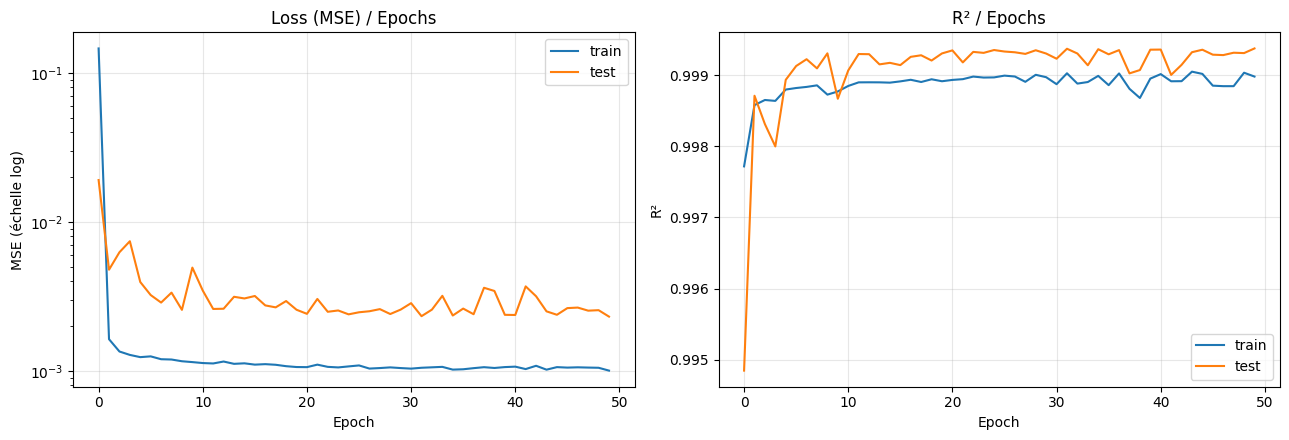

In [74]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(history_lr["train_loss"], label="train")
ax[0].plot(history_lr["test_loss"], label="test")
ax[0].set_title("Loss (MSE) / Epochs")
ax[0].set_xlabel("Epoch"); ax[0].set_yscale("log")
ax[0].set_ylabel("MSE (échelle log)")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(history_lr["train_r2"], label="train")
ax[1].plot(history_lr["test_r2"], label="test")
ax[1].set_title("R² / Epochs")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("R²")
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.savefig("courbes_base.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [75]:
   import numpy as np
   print("Test  (moy. 10 dernières epochs) :", np.mean(history_lr["test_loss"][-10:]))
   print("Train (moy. 10 dernières epochs) :", np.mean(history_lr["train_loss"][-10:]))

Test  (moy. 10 dernières epochs) : 0.0026766163510696193
Train (moy. 10 dernières epochs) : 0.0010447509710126502


on va remplacer train_model par new version pour ajouter weight_decay verbose et early stopping

In [76]:
import copy

def train_model(train_loader, model, test_loader, epochs=50, lr=0.001, opt="adam",
                weight_decay=0.0, verbose=True, val_loader=None, patience=None):
    criterion = nn.MSELoss()
    if opt == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)

    history = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}
    best_val, best_state, wait = float("inf"), None, 0

    for epoch in range(epochs):
        model.train()
        total_loss, n = 0.0, 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(inputs)
            n += len(inputs)

        history["train_loss"].append(total_loss / n)
        history["test_loss"].append(evaluate_model(model, test_loader, criterion))

        model.eval()
        with torch.no_grad():
            p_tr = model(X_train_t.to(device)).cpu().numpy()
            p_te = model(X_test_t.to(device)).cpu().numpy()
        history["train_r2"].append(r2_score(y_train_s, p_tr))
        history["test_r2"].append(r2_score(y_test_s, p_te))

        # early stopping : on surveille une validation, jamais le test
        if patience is not None and val_loader is not None:
            val_loss = evaluate_model(model, val_loader, criterion)
            if val_loss < best_val:
                best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping à l'epoch {epoch+1}")
                    break

        if verbose and (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} | loss train {history['train_loss'][-1]:.4f} "
                  f"test {history['test_loss'][-1]:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)   # on recupere les meilleurs poids 
    return history

une classe de modèle avec Dropout et BatchNorm

In [77]:
class MLPReg(nn.Module):
    def __init__(self, in_features=5, hidden1=32, hidden2=32,
                 activation=nn.ReLU, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], in_features
        for h in (hidden1, hidden2):
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(activation())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, X):
        return self.net(X)

préparer la validation pour l’early stopping

In [80]:
from torch.utils.data import TensorDataset, DataLoader

m = torch.from_numpy((train["date"] < "2015-01-01").values)

train_loader_sub = DataLoader(TensorDataset(X_train_t[m],  y_train_t[m]),  batch_size=64, shuffle=True)
val_loader       = DataLoader(TensorDataset(X_train_t[~m], y_train_t[~m]), batch_size=64)

le model avec early stopping est entrainer seulement sur 2010-2014 donc il a moins de data que les autres

In [81]:
import numpy as np, pandas as pd
crit = nn.MSELoss()

def run(seed=0, wd=0.0, dropout=0.0, batchnorm=False, es=False):
    torch.manual_seed(seed)
    mod = MLPReg(dropout=dropout, batchnorm=batchnorm).to(device)
    if es:
        h = train_model(train_loader_sub, mod, test_loader, epochs=100, weight_decay=wd,
                        verbose=False, val_loader=val_loader, patience=5)
    else:
        h = train_model(train_loader, mod, test_loader, epochs=50, weight_decay=wd, verbose=False)
    return mod, h

configs = {
    "Base":           dict(),
    "L2 (1e-4)":      dict(wd=1e-4),
    "L2 (1e-3)":      dict(wd=1e-3),
    "Dropout 0.1":    dict(dropout=0.1),
    "Dropout 0.2":    dict(dropout=0.2),
    "BatchNorm":      dict(batchnorm=True),
    "Early stopping": dict(es=True),
    "L2 + Dropout":   dict(wd=1e-4, dropout=0.1),
}

rows, histories = [], {}
for name, cfg in configs.items():
    tr, te = [], []
    for seed in [0, 1, 2]:
        mod, h = run(seed=seed, **cfg)
        tr.append(evaluate_model(mod, train_loader, crit))        # train en mode eval
        te.append(evaluate_model(mod, test_loader, crit) if cfg.get("es")
                  else np.mean(h["test_loss"][-10:]))              # moyenne des 10 dernières epochs
    histories[name] = h
    rows.append({"Modèle": name, "Loss train": np.mean(tr), "Loss test": np.mean(te),
                 "± test": np.std(te), "test/train": np.mean(te) / np.mean(tr)})

table = pd.DataFrame(rows)
table.round(5)

Early stopping à l'epoch 29
Early stopping à l'epoch 23
Early stopping à l'epoch 15


,Modèle,Loss train,Loss test,± test,test/train
0,Base,0.00111,0.00300,0.00031,2.71138
1,L2 (1e-4),0.00112,0.00307,0.00029,2.73913
2,L2 (1e-3),0.00114,0.00318,0.00030,2.80424
3,Dropout 0.1,0.00624,0.03205,0.01101,5.13558
4,Dropout 0.2,0.01771,0.08834,0.06463,4.98845
5,BatchNorm,0.00733,0.03172,0.00791,4.32515
6,Early stopping,0.00113,0.00439,0.00123,3.87196
7,L2 + Dropout,0.00612,0.03021,0.01622,4.93742


In [82]:
rows2 = []
for name, cfg in configs.items():
    mod, h = run(seed=0, **cfg)
    mod.eval()
    with torch.no_grad():
        p_tr = scaler_y.inverse_transform(mod(X_train_t.to(device)).cpu().numpy()).ravel()
        p_te = scaler_y.inverse_transform(mod(X_test_t.to(device)).cpu().numpy()).ravel()
    rows2.append({"Modèle": name,
                  "RMSE train ($)": rmse(y_train, p_tr), "RMSE test ($)": rmse(y_test, p_te),
                  "MAPE train (%)": mape(y_train.values, p_tr), "MAPE test (%)": mape(y_test.values, p_te)})

pd.DataFrame(rows2).round(2)

Early stopping à l'epoch 29


,Modèle,RMSE train ($),RMSE test ($),MAPE train (%),MAPE test (%)
0,Base,5.17,8.01,1.40,1.27
1,L2 (1e-4),5.16,7.94,1.37,1.18
2,L2 (1e-3),5.15,8.42,1.48,1.17
3,Dropout 0.1,13.69,34.15,4.60,4.42
4,Dropout 0.2,27.57,67.95,6.71,7.81
5,BatchNorm,18.41,60.07,4.98,6.60
6,Early stopping,5.37,10.88,1.37,1.47
7,L2 + Dropout,14.74,36.53,4.65,4.75


**Interprétation.** Le modèle de base ne sur-apprenait pas : sa loss de test ne remontait pas, et le rapport loss test / loss train (≈ 2,7) n'est réduit par aucune technique. L'écart train/test provient plutôt du décalage de distribution des prix en 2016, que la régularisation ne corrige pas. Aucun modèle régularisé ne bat la baseline naïve « demain = aujourd'hui »

# Synthèse de la Partie 1 : Régression (NYSE)

## 1. Données et problème posé
- Dataset : `prices-split-adjusted.csv` (~851 000 lignes, 501 actions, 2010-2016).
- Sous-ensemble retenu : 4 actions (AAPL, GOOG, AMZN, IBM), soit 7 044 lignes, pour garder un GridSearch rapide.
- Cible : le **close du jour suivant** (`shift(-1)` par action), pour éviter la fuite d'information (`high` et `low` du jour ne sont connus qu'à la clôture).
- Features : `open`, `high`, `low`, `close`, `volume` du jour t.
- Split **chronologique** : train 2010-2015 (6 040 lignes), test 2016 (1 004 lignes). `StandardScaler` ajusté sur le train uniquement.
- 
## 2. Résultats en dollars et comparaison à la baseline

- Les modèles **égalent la baseline sans la dépasser clairement** : ils ont surtout appris à reproduire le close du jour.
- MAPE par action (train) : AAPL 4,44 %, AMZN 1,45 %, GOOG 1,09 %, IBM 0,96 %.
- L'erreur d'AAPL baisse de 10,1 % (2010) à 1,5 % (2015) à mesure que son prix monte : la MSE sur prix bruts ne tient pas compte du niveau de prix.

## 3. Régularisation
- Aucune technique n'améliore le modèle de base, et aucune ne réduit le rapport loss test / loss train (≈ 2,7).
- Interprétation : le modèle ne sur-apprenait pas. L'écart train/test vient plutôt du décalage de distribution, que la régularisation ne corrige pas.
- Limites : une seule graine pour les chiffres en dollars, grille de régularisation réduite.

## 4. Limites et perspectives
- Prédire un prix brut est un problème dominé par « demain ≈ aujourd'hui » : la baseline est très difficile à battre.
- Perspective : prédire le **rendement** (variation en %) avec des features relatives, pour supprimer la dérive de niveau et rendre l'erreur comparable entre actions. Non réalisé ici.

## 5. Ce que j'ai appris
- Mener une EDA qui oriente les choix de modélisation (cible, split, normalisation).
- Construire, entraîner et évaluer un MLP en PyTorch (`nn.Module`, `DataLoader`, boucle d'entraînement).
**La fuite de données est discrète, et il faut la traquer.** Elle peut se glisser à plusieurs endroits : utiliser le `high` et le `low` du jour pour prédire le close du même jour, ajuster le scaler sur tout le dataset, ou mélanger les dates dans la validation croisée. J'ai donc construit la cible avec `shift(-1)`, ajusté le `StandardScaler` uniquement sur le train, et utilisé une validation croisée temporelle (on valide toujours sur une année postérieure à l'entraînement). Je retiens qu'un bon score obtenu avec une fuite est un faux bon score.

**Un GridSearch ne désigne pas toujours un vrai « meilleur » modèle.** En relançant la même grille, le classement a changé : une configuration en tête la première fois est passée 4ᵉ la seconde. Les cinq premières étaient en réalité à égalité, car leurs écarts étaient plus petits que la variabilité due à l'initialisation. J'en retiens qu'il faut regarder l'écart-type, pas seulement la moyenne, et rester honnête quand les différences sont dans le bruit.

**Toujours se comparer à une baseline simple.** Mon modèle atteignait un R² de 0,999, ce qui avait l'air excellent. Mais la règle « le prix de demain sera celui d'aujourd'hui » faisait aussi bien, voire un peu mieux. Sans cette comparaison, j'aurais présenté un résultat impressionnant en apparence mais sans valeur ajoutée. Regarder les résultats par groupe m'a aussi appris des choses : AAPL était bien plus mal prédite que les autres, simplement parce que son prix était bas au début de la période.

**Surapprentissage et décalage de distribution sont deux problèmes différents.** Mon modèle avait une loss de test environ 2,7 fois plus haute que celle du train, ce qui ressemble à du surapprentissage. En réalité, la loss de test ne remontait pas, et l'écart venait du fait que les prix de 2016 étaient plus hauts que ceux du train. Aucune technique de régularisation n'a réduit cet écart, ce qui confirme que la régularisation ne soigne que le surapprentissage. Dropout et BatchNorm ont même dégradé le modèle, qui était déjà petit : ajouter de la régularisation n'est pas toujours une bonne idée.

**Une métrique seule peut tromper.** Le R² est très flatteur quand les valeurs sont grandes et proches les unes des autres, et il n'est pas comparable entre train et test quand leurs variances diffèrent. Le RMSE donne l'erreur en dollars, mais il pénalise surtout les actions chères, alors que le MAPE exprime l'erreur en pourcentage, ce qui rend les actions comparables. Il faut donc croiser plusieurs métriques avant de conclure.

**Ce que je ferais autrement.** Je prédirais le rendement (la variation en %) plutôt que le prix brut, pour supprimer la dérive de niveau et rendre l'erreur comparable d'une action à l'autre. C'est une piste que je n'ai pas eu le temps de tester, mais que je retiens pour la suite.